In [16]:
# !pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 11.7 MB/s eta 0:00:0000:010:01


In [3]:
import os

import pandas as pd
import numpy as np

# store elements as dictionary keys and their counts as dictionary values
from collections import Counter

# scikit-learn
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import make_pipeline

# Classification metrics
from sklearn.metrics import confusion_matrix, classification_report

# Function for creating model pipelines - sklearn
from sklearn.pipeline import make_pipeline

# Function for creating model pipelines - imblearn
from imblearn.pipeline import make_pipeline as imbl_pipe

# Over-sampling using SMOTE
from imblearn.over_sampling import SMOTE


## Load Analytical Base Table

In [37]:
import pandas as pd

# Read the CSV file into a DataFrame
churn_data = pd.read_csv("Churn_Modelling.csv")

# Print the dimensions of the DataFrame
print(f"Dataframe dimensions: {churn_data.shape}")

# Drop specified columns from the DataFrame
churn_data = churn_data.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Display the first few rows of the modified DataFrame
churn_data.head()

Dataframe dimensions: (10000, 14)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Separate dataframe into separate object

In [38]:
# Object for target variable
target_variable = churn_data.Exited

# Object for input features
input_features = churn_data.drop(['Exited'], axis=1)

# Display shapes of input features and target variable
print(input_features.shape, target_variable.shape)

(10000, 10) (10000,)


In [39]:
# List numerical features
num_columns = input_features.select_dtypes(include='number').columns.tolist()
num_columns

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary']

In [40]:
# List categorical features
cat_columns = input_features.select_dtypes(include='object').columns.tolist()
cat_columns

['Geography', 'Gender']

In [8]:
def class_count(a):
    counter=Counter(a)
    kv=[list(counter.keys()),list(counter.values())]
    dff = pd.DataFrame(np.array(kv).T, columns=['Exited','Count'])
    dff['Count'] = dff['Count'].astype('int64')
    dff['%'] = round(dff['Count'] / a.shape[0] * 100, 2)
    return dff.sort_values('Count',ascending=False)

In [41]:
class_count(target_variable)

,Exited,Count,%
1,0,7963,79.63
0,1,2037,20.37


## Create a Train Test Split

In [42]:
random_state = 10

# Split X and y into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(input_features, target_variable, test_size=0.3,
                                                    random_state=random_state,
                                                   stratify=df.Exited)

# Print number of observations in X_train, X_test, y_train, and y_test
print(len(X_train), len(X_test), len(y_train), len(y_test))

7000 3000 7000 3000


In [43]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 8061 to 4741
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      7000 non-null   int64  
 1   Geography        7000 non-null   object 
 2   Gender           7000 non-null   object 
 3   Age              7000 non-null   int64  
 4   Tenure           7000 non-null   int64  
 5   Balance          7000 non-null   float64
 6   NumOfProducts    7000 non-null   int64  
 7   HasCrCard        7000 non-null   int64  
 8   IsActiveMember   7000 non-null   int64  
 9   EstimatedSalary  7000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 601.6+ KB


## Pre-processing Pipeline

### Scale numerical data and encode categorical data
Construct a pre-processing pipeline from the given transformers: MinMaxScaler and OneHotEncoder

Create lists of indexes from the list of column names

Need to be numeric not string to specify columns name in column transformer

In [44]:
num_features = [] 

for i in num_columns:
    location = X.columns.get_loc(i)
    num_features.append(location)
print(num_features)  

[0, 3, 4, 5, 6, 7, 8, 9]


In [45]:
cat_features = []

for i in cat_columns:
    location = X.columns.get_loc(i)
    cat_features.append(location)
print(cat_features)  

[1, 2]


In [46]:
# Define column transformer
# Need to be numeric not string to specify columns name 
preprocess = make_column_transformer(
    (MinMaxScaler(), num_features),
    (OneHotEncoder(), cat_features)
)
preprocess

ColumnTransformer(transformers=[('minmaxscaler', MinMaxScaler(),
                                 [0, 3, 4, 5, 6, 7, 8, 9]),
                                ('onehotencoder', OneHotEncoder(), [1, 2])])

## Build Model Pipeline with SMOTE

* We are going to use the Pipeline from the imblearn package in place of scikit-learn Pipeline.

* It takes care automatically to re-sample when called fit() on the pipeline, and does not re-sample test data (when called transform() or predict()).

In [47]:
# Import XGBoost
import xgboost as xgb

# Define model with pipeline
model = imbl_pipe(preprocess,
                  SMOTE(sampling_strategy='auto', random_state=random_state),
                  xgb.XGBClassifier(use_label_encoder=False, random_state=random_state))

model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('minmaxscaler',
                                                  MinMaxScaler(),
                                                  [0, 3, 4, 5, 6, 7, 8, 9]),
                                                 ('onehotencoder',
                                                  OneHotEncoder(), [1, 2])])),
                ('smote', SMOTE(random_state=10)),
                ('xgbclassifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               e...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, random_state=10, ...))])

In [48]:
xgb.XGBClassifier().get_params()

{'objective': 'binary:logistic',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': None,
 'feature_types': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': None,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': None,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': None,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None}

In [49]:
# Create the GridSearchCV model
# Create the GridSearch estimator along with a parameter object containing the values to adjust
from sklearn.model_selection import GridSearchCV

param_grid = {'xgbclassifier__gamma': [0.5, 0.8, 1],
              'xgbclassifier__max_depth': [3, 4, 5, 6],
              'xgbclassifier__n_estimators': [50, 100, 200]
        }
grid = GridSearchCV(model, param_grid, verbose=3, cv= 5, n_jobs=4, scoring='f1_macro')


In [50]:
X_train = X_train.values
X_test = X_test.values

In [67]:
# Train the model with GridSearch
grid.fit(X_train, y_train, xgbclassifier__eval_metric='logloss')


Fitting 5 folds for each of 36 candidates, totalling 180 fits


/Users/balagopinathkuchibatla/main/BackUp1/Desktop/Maters Info/Admitted Universities/IIT Chicgo/coursework/2_Spring24/Machine learning/final_project/venv/lib/python3.12/site-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/Users/balagopinathkuchibatla/main/BackUp1/Desktop/Maters Info/Admitted Universities/IIT Chicgo/coursework/2_Spring24/Machine learning/final_project/venv/lib/python3.12/site-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/Users/balagopinathkuchibatla/main/BackUp1/Desktop/Maters Info/Admitted Universities/IIT Chicgo/coursework/2_Spring24/Machine learning/final_project/venv/lib/python3.12/site-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('minmaxscaler',
                                                                         MinMaxScaler(),
                                                                         [0, 3,
                                                                          4, 5,
                                                                          6, 7,
                                                                          8,
                                                                          9]),
                                                                        ('onehotencoder',
                                                                         OneHotEncoder(),
                                                                         [1,
                                                                          2])])),
                                       ('smote', SMOTE(random_state=10)),
                                       ('xgbclassifier',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsamp...
                                                      max_depth=None,
                                                      max_leaves=None,
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=None,
                                                      num_parallel_tree=None,
                                                      random_state=10, ...))]),
             n_jobs=4,
             param_grid={'xgbclassifier__gamma': [0.5, 0.8, 1],
                         'xgbclassifier__max_depth': [3, 4, 5, 6],
                         'xgbclassifier__n_estimators': [50, 100, 200]},
             scoring='f1_macro', verbose=3)

In [68]:
print(grid.best_params_)

{'xgbclassifier__gamma': 0.8, 'xgbclassifier__max_depth': 4, 'xgbclassifier__n_estimators': 100}


In [69]:
 # List the best score
print(grid.best_score_)

0.7612982384579798


In [70]:
print(f"Training Data Score: {grid.score(X_train, y_train)}")
print(f"Testing Data Score: {grid.score(X_test, y_test)}")

Training Data Score: 0.8106322732916824
Testing Data Score: 0.766781181961393


In [71]:
# Make predictions with the hypertuned model
pred = grid.predict(X_test)
pred

array([0, 0, 0, ..., 0, 0, 0])

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

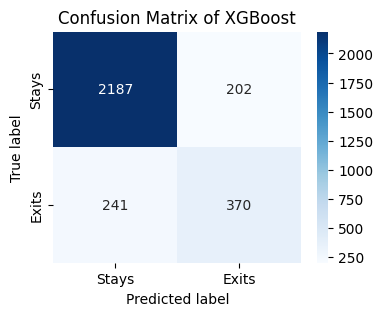

In [73]:
# Assuming you already have defined cm and printed it
cm = confusion_matrix(y_test, pred)
# Plotting the confusion matrix as a heatmap
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', 
            xticklabels=['Stays', 'Exits'], 
            yticklabels=['Stays', 'Exits'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix of XGBoost')
plt.show()


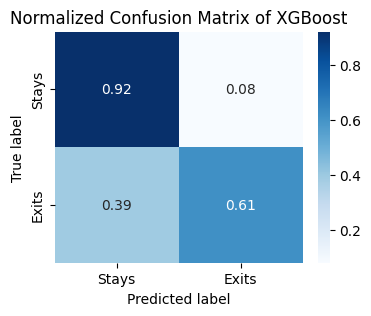

In [74]:
# Assuming you already have defined cm and printed it
cm_normalized =np.around(cm / cm.sum(axis=1)[:, np.newaxis], 2)
# Plotting the normalized confusion matrix as a heatmap
plt.figure(figsize=(4, 3))
sns.heatmap(cm_normalized, annot=True, cmap='Blues', 
            xticklabels=['Stays', 'Exits'], 
            yticklabels=['Stays', 'Exits'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Normalized Confusion Matrix of XGBoost')
plt.show()

In [75]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.90      0.92      0.91      2389
           1       0.65      0.61      0.63       611

    accuracy                           0.85      3000
   macro avg       0.77      0.76      0.77      3000
weighted avg       0.85      0.85      0.85      3000



In [76]:
print(f"Predicted classes: \t{list(pred[:10])}")
print(f"Actual Labels: \t\t{list(y_test[:10])}")

Predicted classes: 	[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
Actual Labels: 		[1, 0, 0, 0, 0, 1, 0, 0, 0, 0]


## Save the Model

In [77]:
import joblib

# We are saving our grid model
filename = 'XGBoost_model.sav'
joblib.dump(grid, filename)

['XGBoost_model.sav']

## Loading the Model

In [78]:
# load the model
xgb_model = joblib.load(filename)
print(xgb_model.score(X_test, y_test))

0.766781181961393


### Predict class for new data

In [79]:
# Let's use the first X_test record as new data
X_test[:1]

array([[638, 'France', 'Male', 36, 6, 188455.19, 1, 0, 0, 47031.4]],
      dtype=object)

In [80]:
pred_new = xgb_model.predict(X_test[:1])

In [81]:
print(f"Predicted classes: \t{pred_new}")
print(f"Actual Labels: \t\t{list(y_test[:1])}")

Predicted classes: 	[0]
Actual Labels: 		[1]
[CV 3/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=3, xgbclassifier__n_estimators=50;, score=0.734 total time=   0.0s
[CV 1/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=3, xgbclassifier__n_estimators=100;, score=0.760 total time=   0.1s
[CV 5/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=3, xgbclassifier__n_estimators=100;, score=0.766 total time=   0.1s
[CV 4/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=3, xgbclassifier__n_estimators=200;, score=0.759 total time=   0.1s
[CV 4/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=4, xgbclassifier__n_estimators=50;, score=0.758 total time=   0.0s
[CV 3/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=4, xgbclassifier__n_estimators=100;, score=0.745 total time=   0.1s
[CV 2/5] END xgbclassifier__gamma=0.5, xgbclassifier__max_depth=4, xgbclassifier__n_estimators=200;, score=0.749 total time=   0.1s
[CV 5/5] END xgbclassifier__gamma